In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_all = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
df_all.model.unique()

array(['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR',
       'UKESM1-0-LL'], dtype=object)

7
12
6
8
8
9


(-3.0, 3.0)

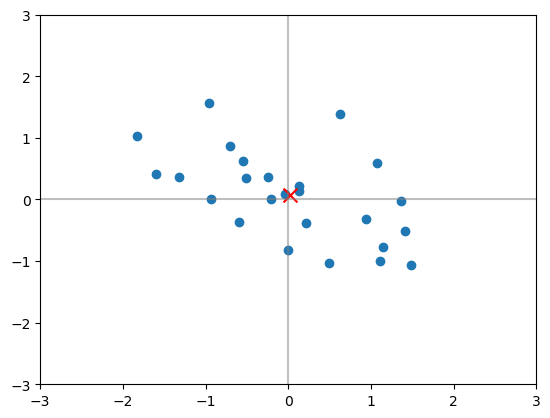

In [3]:
df_can = df_all.where(df_all['model']=='CanESM5').dropna()
ens = []
for i in range(1,26):
    ens.append('r' + str(i) + 'i1p2f1')
df_can = df_all.where(df_all['model']=='CanESM5').dropna()
df_can = df_can.set_index('realization').loc[ens]

print(sum(df_can['enso_flag'] == 1))
print(sum(df_can['enso_flag'] == 0))
print(sum(df_can['enso_flag'] == -1))
print(sum(df_can['nao_flag'] == 1))
print(sum(df_can['nao_flag'] == 0))
print(sum(df_can['nao_flag'] == -1))

plt.scatter(df_can['nao'], df_can['enso'])
plt.scatter(np.mean(df_can['nao']), np.mean(df_can['enso']), color='red', marker='x', s=100)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.,3)

11
11
18


(-3.0, 3.0)

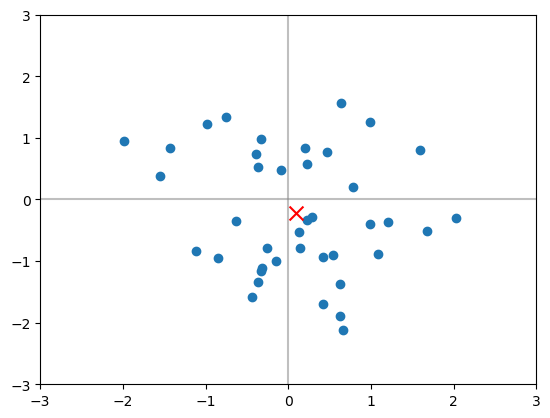

In [4]:
df_giss = df_all.where(df_all['model']=='GISS-E2-1-G').dropna()

print(sum(df_giss['enso_flag'] == 1))
print(sum(df_giss['enso_flag'] == 0))
print(sum(df_giss['enso_flag'] == -1))

plt.scatter(df_giss['nao'], df_giss['enso'])
plt.scatter(np.mean(df_giss['nao']), np.mean(df_giss['enso']), color='red', marker='x', s=100)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.,3)

12
10
3


(-3.0, 3.0)

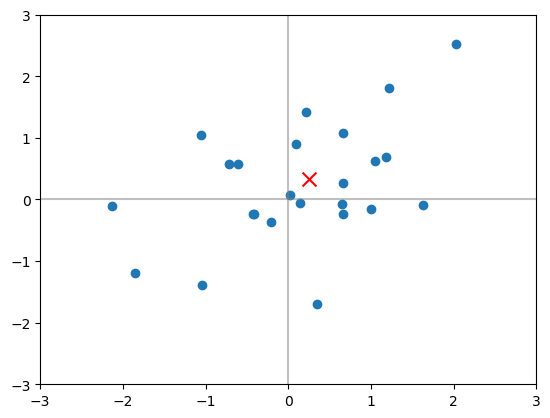

In [5]:
df_miroc = df_all.where(df_all['model']=='MIROC-ES2L').dropna()

print(sum(df_miroc['enso_flag'] == 1))
print(sum(df_miroc['enso_flag'] == 0))
print(sum(df_miroc['enso_flag'] == -1))

plt.scatter(df_miroc['nao'], df_miroc['enso'])
plt.scatter(np.mean(df_miroc['nao']), np.mean(df_miroc['enso']), color='red', marker='x', s=100)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.,3)

8
7
10


(-3.0, 3.0)

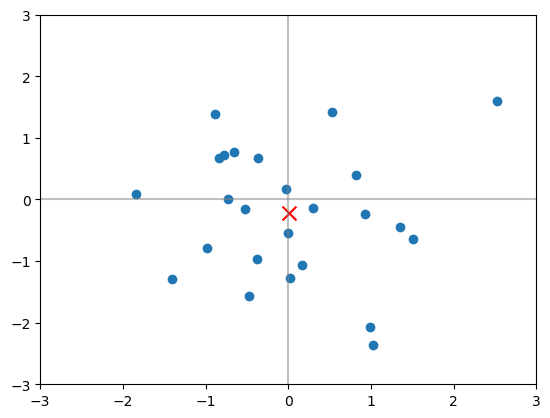

In [6]:
df_mpi = df_all.where(df_all['model']=='MPI-ESM1-2-LR').dropna()

print(sum(df_mpi['enso_flag'] == 1))
print(sum(df_mpi['enso_flag'] == 0))
print(sum(df_mpi['enso_flag'] == -1))

plt.scatter(df_mpi['nao'], df_mpi['enso'])
plt.scatter(np.mean(df_mpi['nao']), np.mean(df_mpi['enso']), color='red', marker='x', s=100)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.,3)

8
10
7


(-3.0, 3.0)

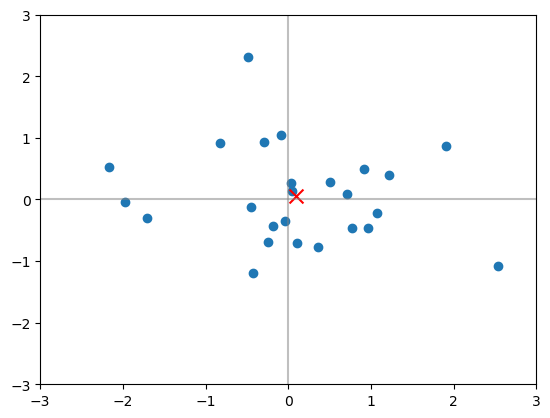

In [7]:
df_ukesm = df_all.where(df_all['model']=='UKESM1-0-LL').dropna()

print(sum(df_ukesm['enso_flag'] == 1))
print(sum(df_ukesm['enso_flag'] == 0))
print(sum(df_ukesm['enso_flag'] == -1))

plt.scatter(df_ukesm['nao'], df_ukesm['enso'])
plt.scatter(np.mean(df_ukesm['nao']), np.mean(df_ukesm['enso']), color='red', marker='x', s=100)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.,3)

In [8]:
df_all[['enso', 'nao', 'model']].groupby('model').mean()

,enso,nao
model,,
CanESM5,0.034777,0.017995
GISS-E2-1-G,-0.223877,0.090819
MIROC-ES2L,0.331379,0.257298
MPI-ESM1-2-LR,-0.225194,0.010897
UKESM1-0-LL,0.058561,0.090389


In [9]:
def create_label(data, name):
    enso_part = str(sum(data['enso_flag'] == -1)) + ' '+  str(sum(data['enso_flag'] == 0))+ ' ' + str(sum(data['enso_flag'] == 1))
    nao_part = str(sum(data['nao_flag'] == -1)) + ' '+  str(sum(data['nao_flag'] == 0))+ ' ' + str(sum(data['nao_flag'] == 1))
    return name + ' (E: ' + enso_part + '; N: ' + nao_part + ')'

In [10]:
label_can = create_label(df_can, 'CanESM5')
label_giss = create_label(df_giss, 'GISS-E2-1-G')
label_miroc = create_label(df_miroc, 'MIROC-ES2L')
label_mpi = create_label(df_mpi, 'MPI-ESM1-2-LR')
label_ukesm = create_label(df_ukesm, 'UKESM1-0-LL')

labels = [label_can, label_giss, label_miroc, label_mpi, label_ukesm]

In [11]:
labels

['CanESM5 (E: 6 12 7; N: 9 8 8)',
 'GISS-E2-1-G (E: 18 11 11; N: 8 19 13)',
 'MIROC-ES2L (E: 3 10 12; N: 6 8 11)',
 'MPI-ESM1-2-LR (E: 10 7 8; N: 10 7 8)',
 'UKESM1-0-LL (E: 7 10 8; N: 7 9 9)']

In [12]:
df_all = pd.concat([df_can, df_giss, df_miroc, df_mpi, df_ukesm])

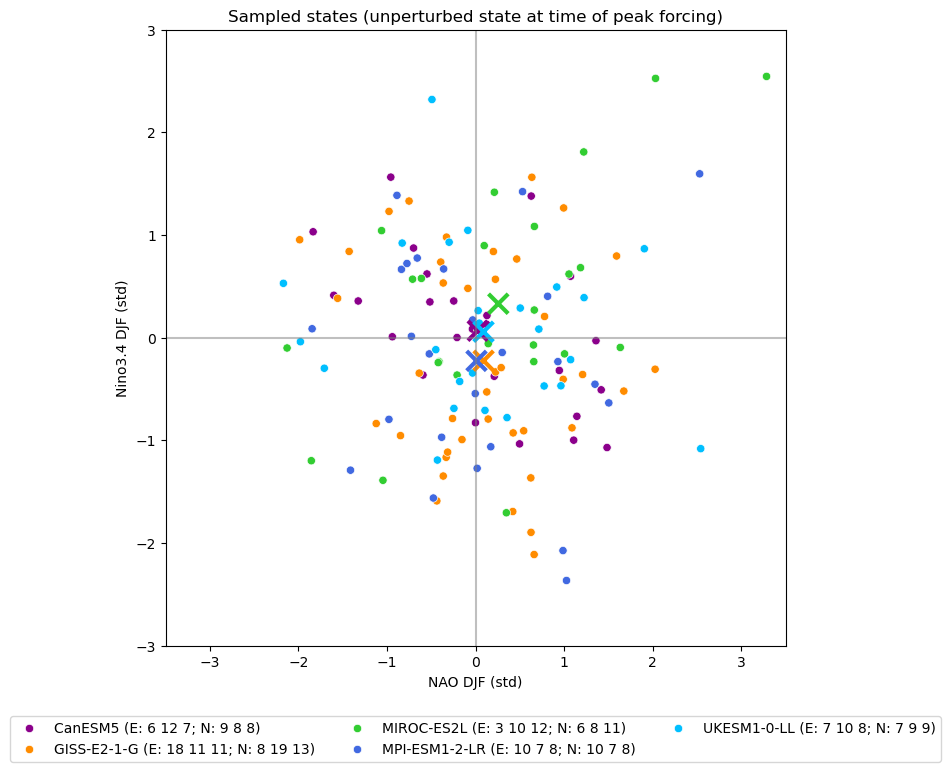

In [15]:
import seaborn as sns
fig = plt.figure(figsize=(8,8))
#hue_order = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
ax = sns.scatterplot(data=df_all, x='nao', y='enso', hue='model', palette=['darkmagenta', 'darkorange',  'limegreen', 'royalblue', 'deepskyblue'])
ax.legend().set_title(None)
sns.scatterplot(data=df_all[['enso', 'nao', 'model']].groupby('model').mean(), x='nao', y='enso', hue='model',   palette=['darkmagenta', 'darkorange',  'limegreen', 'royalblue', 'deepskyblue'], s=200, linewidth=3, marker='x', legend=False)
plt.vlines(0, -3., 3., color='grey', linestyle='-', alpha=0.5)
plt.hlines(0, -3.5, 3.5, color='grey', linestyle='-', alpha=0.5)
plt.ylim(-3.,3)
plt.xlim(-3.5,3.5)
plt.xlabel('NAO DJF (std)')
plt.ylabel('Nino3.4 DJF (std)')
plt.title('Sampled states (unperturbed state at time of peak forcing)')
sns.move_legend(obj=ax, loc="lower center", labels=labels, ncol=3, bbox_to_anchor=(0.5, -0.2))

plt.savefig('/home/kperny/VolMIP_stratosphere/plots/sampled_states_ENSOandNAO.png', bbox_inches='tight', dpi=200)